**Supervised machine learning** means training a model using labeled data, where you have:
- Input (features/X): the information the model uses to make a prediction.
- Expected target (label/y): the correct answer you want the model to learn.


### glob
Go into this folder and find all files that match this pattern

When many files have a predictable naming pattern, glob saves you from manually writing every file path by using a wildcard (*) to find all matching files automatically.

Hard-coding a list of filenames creates brittle code — the moment a filename changes or a sixth year of data is added, your script breaks silently or requires manual editing. glob is the robust alternative: it finds whatever files match the pattern at runtime, making the pipeline self-updating as new data arrives.

In [1]:
import pandas as pd
import numpy as np
from glob import glob
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
datasets=glob("../data/buenos-aires-real-estate-*.csv")
datasets

['../data/buenos-aires-real-estate-3.csv',
 '../data/buenos-aires-real-estate-2.csv',
 '../data/buenos-aires-real-estate-1.csv',
 '../data/buenos-aires-real-estate-5.csv',
 '../data/buenos-aires-real-estate-4.csv']

In [3]:
files=[]
for dataset in datasets:
    data=pd.read_csv(dataset)
    files.append(data)
len(files)


5

In [4]:
df=pd.concat(files,ignore_index=True)

In [5]:
df.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Moreno|Mor...,NaN,180000.0,USD,2729232.0,180000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://moreno.properati.com.ar/10rhr_venta_cas...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|,"-34.6624160375,-58.6044728878",125000.0,USD,1895300.0,125000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://moron-bs-as-g-b-a-zona-oeste.properati....
2,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Sur|Lanús|Lanús|,"-34.7033677191,-58.3923923872",175000.0,USD,2653420.0,175000.0,100.0,92.0,1750.0,1902.173913,NaN,4.0,2.0,http://lanus.properati.com.ar/pzqo_venta_depar...
3,sell,PH,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,NaN,NaN,NaN,NaN,199.0,110.0,NaN,NaN,NaN,3.0,NaN,http://ramos-mejia.properati.com.ar/sat2_venta...
4,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Oeste|Ituzaingó|...,NaN,90000.0,USD,1364616.0,90000.0,NaN,70.0,NaN,1285.714286,NaN,3.0,NaN,http://ituzaingo.properati.com.ar/smi9_venta_d...


In [6]:
def merge_files(data):
    return pd.concat([pd.read_csv(file) for file in glob(data)],ignore_index=True)

In [7]:
merge_files("../data/buenos-aires-real-estate-*.csv").info()

<class 'pandas.DataFrame'>
RangeIndex: 43029 entries, 0 to 43028
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   43029 non-null  str    
 1   property_type               43029 non-null  str    
 2   place_with_parent_names     43029 non-null  str    
 3   lat-lon                     34734 non-null  str    
 4   price                       38073 non-null  float64
 5   currency                    38072 non-null  str    
 6   price_aprox_local_currency  38073 non-null  float64
 7   price_aprox_usd             38073 non-null  float64
 8   surface_total_in_m2         29871 non-null  float64
 9   surface_covered_in_m2       36420 non-null  float64
 10  price_usd_per_m2            24449 non-null  float64
 11  price_per_m2                32642 non-null  float64
 12  floor                       6505 non-null   float64
 13  rooms                       23806 non-null

## Data Cleaning

In [8]:
df["place_with_parent_names"].unique()

<StringArray>
[                     '|Argentina|Bs.As. G.B.A. Zona Oeste|Moreno|Moreno|',
                              '|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|',
                          '|Argentina|Bs.As. G.B.A. Zona Sur|Lanús|Lanús|',
             '|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza|Ramos Mejía|',
                '|Argentina|Bs.As. G.B.A. Zona Oeste|Ituzaingó|Ituzaingó|',
             '|Argentina|Bs.As. G.B.A. Zona Norte|San Miguel|Bella Vista|',
                             '|Argentina|Bs.As. G.B.A. Zona Oeste|Moreno|',
                         '|Argentina|Capital Federal|Villa General Mitre|',
 '|Argentina|Bs.As. G.B.A. Zona Norte|General San Martín|Villa Ballester|',
                    '|Argentina|Bs.As. G.B.A. Zona Norte|Tigre|Benavidez|',
 ...
   '|Argentina|Bs.As. G.B.A. Zona Norte|Escobar|Barrio Cerrado El Lucero|',
   '|Argentina|Bs.As. G.B.A. Zona Sur|Almirante Brown|Ministro Rivadavia|',
         '|Argentina|Bs.As. G.B.A. Zona Sur|Quilmes|San Francisco Sol

In [9]:
df.loc[lambda x:x["property_type"] == "apartment"]

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
2,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Sur|Lanús|Lanús|,"-34.7033677191,-58.3923923872",175000.0,USD,2653420.00,175000.00,100.0,92.0,1750.000000,1902.173913,NaN,4.0,2.0,http://lanus.properati.com.ar/pzqo_venta_depar...
4,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Oeste|Ituzaingó|...,NaN,90000.0,USD,1364616.00,90000.00,NaN,70.0,NaN,1285.714286,NaN,3.0,NaN,http://ituzaingo.properati.com.ar/smi9_venta_d...
6,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Oeste|Moreno|,"-34.6501996137,-58.7923693657",85000.0,USD,1288804.00,85000.00,68.0,68.0,1250.000000,1250.000000,NaN,NaN,NaN,http://moreno-bs-as-g-b-a-zona-oeste.properati...
7,sell,apartment,|Argentina|Capital Federal|Villa General Mitre|,"-34.616004,-58.470506",120000.0,USD,1819488.00,120000.00,NaN,55.0,NaN,2181.818182,NaN,2.0,NaN,http://villa-general-mitre.properati.com.ar/xx...
8,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|General Sa...,"-34.5525858,-58.560368",NaN,NaN,NaN,NaN,57.0,50.0,NaN,NaN,1.0,2.0,NaN,http://villa-ballester.properati.com.ar/yolx_v...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43023,sell,apartment,|Argentina|Capital Federal|San Telmo|,"-34.6233348,-58.3748384",85267.0,USD,1292852.36,85267.00,40.0,38.0,2131.675000,2243.868421,NaN,1.0,NaN,http://san-telmo.properati.com.ar/vayv_venta_d...
43024,sell,apartment,|Argentina|Capital Federal|Barracas|,"-34.631213,-58.371545",1200000.0,ARS,1196669.37,78923.48,NaN,50.0,NaN,24000.000000,NaN,2.0,NaN,http://barracas.properati.com.ar/11bzh_venta_d...
43025,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.5625,-58.458333",240000.0,USD,3638976.00,240000.00,55.0,44.0,4363.636364,5454.545455,NaN,2.0,NaN,http://palermo.properati.com.ar/ounv_venta_dep...
43026,sell,apartment,|Argentina|Capital Federal|Villa Luro|,"-34.6444745,-58.4959441",844779.0,ARS,842434.31,55560.75,0.0,38.0,NaN,22231.026320,NaN,1.0,NaN,http://villa-luro.properati.com.ar/sj8e_venta_...


In [10]:
df.query('property_type == "apartment"')

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
2,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Sur|Lanús|Lanús|,"-34.7033677191,-58.3923923872",175000.0,USD,2653420.00,175000.00,100.0,92.0,1750.000000,1902.173913,NaN,4.0,2.0,http://lanus.properati.com.ar/pzqo_venta_depar...
4,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Oeste|Ituzaingó|...,NaN,90000.0,USD,1364616.00,90000.00,NaN,70.0,NaN,1285.714286,NaN,3.0,NaN,http://ituzaingo.properati.com.ar/smi9_venta_d...
6,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Oeste|Moreno|,"-34.6501996137,-58.7923693657",85000.0,USD,1288804.00,85000.00,68.0,68.0,1250.000000,1250.000000,NaN,NaN,NaN,http://moreno-bs-as-g-b-a-zona-oeste.properati...
7,sell,apartment,|Argentina|Capital Federal|Villa General Mitre|,"-34.616004,-58.470506",120000.0,USD,1819488.00,120000.00,NaN,55.0,NaN,2181.818182,NaN,2.0,NaN,http://villa-general-mitre.properati.com.ar/xx...
8,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|General Sa...,"-34.5525858,-58.560368",NaN,NaN,NaN,NaN,57.0,50.0,NaN,NaN,1.0,2.0,NaN,http://villa-ballester.properati.com.ar/yolx_v...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43023,sell,apartment,|Argentina|Capital Federal|San Telmo|,"-34.6233348,-58.3748384",85267.0,USD,1292852.36,85267.00,40.0,38.0,2131.675000,2243.868421,NaN,1.0,NaN,http://san-telmo.properati.com.ar/vayv_venta_d...
43024,sell,apartment,|Argentina|Capital Federal|Barracas|,"-34.631213,-58.371545",1200000.0,ARS,1196669.37,78923.48,NaN,50.0,NaN,24000.000000,NaN,2.0,NaN,http://barracas.properati.com.ar/11bzh_venta_d...
43025,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.5625,-58.458333",240000.0,USD,3638976.00,240000.00,55.0,44.0,4363.636364,5454.545455,NaN,2.0,NaN,http://palermo.properati.com.ar/ounv_venta_dep...
43026,sell,apartment,|Argentina|Capital Federal|Villa Luro|,"-34.6444745,-58.4959441",844779.0,ARS,842434.31,55560.75,0.0,38.0,NaN,22231.026320,NaN,1.0,NaN,http://villa-luro.properati.com.ar/sj8e_venta_...


In [11]:
(
    df
    .loc[lambda x: x["place_with_parent_names"].str.contains("Capital Federal")]
    .query('property_type=="apartment"')
    .query('price_aprox_usd < 400000')
    .head()
)

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
7,sell,apartment,|Argentina|Capital Federal|Villa General Mitre|,"-34.616004,-58.470506",120000.0,USD,1819488.00,120000.0,NaN,55.0,NaN,2181.818182,NaN,2.0,NaN,http://villa-general-mitre.properati.com.ar/xx...
14,sell,apartment,|Argentina|Capital Federal|Recoleta|,"-34.5927179628,-58.3950410728",129500.0,USD,1963530.80,129500.0,35.0,30.0,3700.000000,4316.666667,6.0,1.0,NaN,http://recoleta.properati.com.ar/yxmy_venta_de...
16,sell,apartment,|Argentina|Capital Federal|Villa Urquiza|,"-34.5731507,-58.482362",72039.0,USD,1092284.13,72039.0,26.0,22.0,2770.730769,3274.500000,NaN,1.0,1000.0,http://villa-urquiza.properati.com.ar/12q1e_ve...
17,sell,apartment,|Argentina|Capital Federal|Caballito|,"-34.6170265,-58.4484746",75500.0,USD,1144761.20,75500.0,51.0,29.0,1480.392157,2603.448276,6.0,1.0,900.0,http://caballito.properati.com.ar/ypxg_venta_d...
20,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.584712,-58.444927",89000.0,USD,1349453.60,89000.0,NaN,37.0,NaN,2405.405405,7.0,2.0,NaN,http://palermo.properati.com.ar/ya5i_venta_dep...


In [12]:
def filter_df(data):
   return (
        data
            .loc[lambda x: x["place_with_parent_names"].str.contains("Capital Federal")]
            .query('property_type=="apartment"')
            .query('price_aprox_usd < 400000')
            
    )

In [13]:
filter_df(df)

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
7,sell,apartment,|Argentina|Capital Federal|Villa General Mitre|,"-34.616004,-58.470506",120000.0,USD,1819488.00,120000.00,NaN,55.0,NaN,2181.818182,NaN,2.0,NaN,http://villa-general-mitre.properati.com.ar/xx...
14,sell,apartment,|Argentina|Capital Federal|Recoleta|,"-34.5927179628,-58.3950410728",129500.0,USD,1963530.80,129500.00,35.0,30.0,3700.000000,4316.666667,6.0,1.0,NaN,http://recoleta.properati.com.ar/yxmy_venta_de...
16,sell,apartment,|Argentina|Capital Federal|Villa Urquiza|,"-34.5731507,-58.482362",72039.0,USD,1092284.13,72039.00,26.0,22.0,2770.730769,3274.500000,NaN,1.0,1000.0,http://villa-urquiza.properati.com.ar/12q1e_ve...
17,sell,apartment,|Argentina|Capital Federal|Caballito|,"-34.6170265,-58.4484746",75500.0,USD,1144761.20,75500.00,51.0,29.0,1480.392157,2603.448276,6.0,1.0,900.0,http://caballito.properati.com.ar/ypxg_venta_d...
20,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.584712,-58.444927",89000.0,USD,1349453.60,89000.00,NaN,37.0,NaN,2405.405405,7.0,2.0,NaN,http://palermo.properati.com.ar/ya5i_venta_dep...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43017,sell,apartment,|Argentina|Capital Federal|Villa General Mitre|,"-34.6148346,-58.4663066",227000.0,USD,3441864.80,227000.00,126.0,84.0,1801.587302,2702.380952,NaN,4.0,3200.0,http://villa-general-mitre.properati.com.ar/vi...
43023,sell,apartment,|Argentina|Capital Federal|San Telmo|,"-34.6233348,-58.3748384",85267.0,USD,1292852.36,85267.00,40.0,38.0,2131.675000,2243.868421,NaN,1.0,NaN,http://san-telmo.properati.com.ar/vayv_venta_d...
43024,sell,apartment,|Argentina|Capital Federal|Barracas|,"-34.631213,-58.371545",1200000.0,ARS,1196669.37,78923.48,NaN,50.0,NaN,24000.000000,NaN,2.0,NaN,http://barracas.properati.com.ar/11bzh_venta_d...
43025,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.5625,-58.458333",240000.0,USD,3638976.00,240000.00,55.0,44.0,4363.636364,5454.545455,NaN,2.0,NaN,http://palermo.properati.com.ar/ounv_venta_dep...


## Why Outliers Harm Linear Regression

**1. Linear regression minimizes the Sum of Squared Errors (SSE).**

* A residual is the difference between the actual value and the predicted value.
* SSE is the sum of all squared residuals.

**2. Why are outliers a problem?**

Squaring errors gives large errors much more weight than small errors.

Example:

* Error of 10 → squared error = 100
* Error of 100 → squared error = 10,000

An error of 100 contributes 100 times more to SSE than an error of 10.

**3. How do outliers affect the regression line?**

An extreme data point can pull or tilt the best-fit line toward itself. This can make predictions less accurate for most typical observations.

Ordinary least squares regression is therefore sensitive to outliers.

**4. What does this mean for real estate data?**

In a property dataset, a few extremely expensive properties may influence the regression model because their prediction errors can be very large.

However, expensive properties are not automatically errors. They may be genuine luxury properties with features that the dataset does not capture.

**5. Key takeaway**

* Investigate extreme values before removing them.
* Use statistical methods such as the IQR rule to identify potential outliers.
* Compare model performance with and without extreme observations.
* Choose the approach that best serves the intended prediction goal.

**Remember:** The goal is not simply to remove outliers, but to build a model that predicts accurately for the properties you want to study.


In [14]:
data.loc[lambda x:x["surface_covered_in_m2"].between(
    x["surface_covered_in_m2"].quantile(0.1),x["surface_covered_in_m2"].quantile(0.9))]

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,house,|Argentina|Capital Federal|Villa Devoto|,"-34.596475,-58.513517",264000.0,USD,4002873.60,264000.00,NaN,155.0,NaN,1703.225806,NaN,4.0,NaN,http://villa-devoto.properati.com.ar/11p6p_ven...
1,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|Pilar|Del ...,"-34.4437805,-58.8438408",86000.0,USD,1303966.40,86000.00,56.0,50.0,1535.714286,1720.000000,NaN,2.0,1800.0,http://del-viso.properati.com.ar/12izd_venta_d...
3,sell,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|Vicente Ló...,"-34.5338568,-58.4804753",149000.0,USD,2259197.60,149000.00,64.0,57.0,2328.125000,2614.035088,NaN,3.0,NaN,http://florida.properati.com.ar/115bk_venta_de...
5,sell,house,|Argentina|Bs.As. G.B.A. Zona Sur|Almirante Br...,"-34.8343743,-58.3976893",180000.0,USD,2729232.00,180000.00,430.0,256.0,418.604651,703.125000,NaN,NaN,NaN,http://burzaco.properati.com.ar/fzzu_venta_cas...
7,sell,house,|Argentina|Capital Federal|Floresta|,"-34.6187838,-58.493994",239000.0,USD,3623813.60,239000.00,225.0,85.0,1062.222222,2811.764706,NaN,3.0,NaN,http://floresta.properati.com.ar/12u1e_venta_c...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8601,sell,apartment,|Argentina|Capital Federal|Barracas|,"-34.631213,-58.371545",1200000.0,ARS,1196669.37,78923.48,NaN,50.0,NaN,24000.000000,NaN,2.0,NaN,http://barracas.properati.com.ar/11bzh_venta_d...
8602,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.5625,-58.458333",240000.0,USD,3638976.00,240000.00,55.0,44.0,4363.636364,5454.545455,NaN,2.0,NaN,http://palermo.properati.com.ar/ounv_venta_dep...
8603,sell,apartment,|Argentina|Capital Federal|Villa Luro|,"-34.6444745,-58.4959441",844779.0,ARS,842434.31,55560.75,0.0,38.0,NaN,22231.026320,NaN,1.0,NaN,http://villa-luro.properati.com.ar/sj8e_venta_...
8604,sell,PH,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza|,"-34.6841757279,-58.5049403685",55000.0,USD,833932.00,55000.00,70.0,70.0,785.714286,785.714286,NaN,NaN,NaN,http://la-matanza.properati.com.ar/xwus_venta_...


In [15]:
def outliers_df(data):
    return (
        data.loc[lambda x:x["surface_covered_in_m2"].between(
    x["surface_covered_in_m2"].quantile(0.1),x["surface_covered_in_m2"].quantile(0.9))]
    )

In [16]:
check_outliers=outliers_df(df)
check_outliers.info()

<class 'pandas.DataFrame'>
Index: 29247 entries, 2 to 43028
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   29247 non-null  str    
 1   property_type               29247 non-null  str    
 2   place_with_parent_names     29247 non-null  str    
 3   lat-lon                     23338 non-null  str    
 4   price                       26963 non-null  float64
 5   currency                    26962 non-null  str    
 6   price_aprox_local_currency  26963 non-null  float64
 7   price_aprox_usd             26963 non-null  float64
 8   surface_total_in_m2         22538 non-null  float64
 9   surface_covered_in_m2       29247 non-null  float64
 10  price_usd_per_m2            18931 non-null  float64
 11  price_per_m2                26962 non-null  float64
 12  floor                       5441 non-null   float64
 13  rooms                       18480 non-null  flo

In [42]:
def modify_cols(data):
    return(
        data.assign(
            lat=lambda x:x["lat-lon"].str.split(",",expand=True)[0].astype(float),
            lon=lambda x:x["lat-lon"].str.split(",",expand=True)[1].astype(float),
            neighbourhood=lambda x:x["place_with_parent_names"].str.split("|",expand=True)[3]
        )
        .dropna(subset=["lat","lon"])
    )
check_cols=modify_cols(df)
check_cols.info()

<class 'pandas.DataFrame'>
Index: 34734 entries, 1 to 43028
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   34734 non-null  str    
 1   property_type               34734 non-null  str    
 2   place_with_parent_names     34734 non-null  str    
 3   lat-lon                     34734 non-null  str    
 4   price                       30968 non-null  float64
 5   currency                    30968 non-null  str    
 6   price_aprox_local_currency  30968 non-null  float64
 7   price_aprox_usd             30968 non-null  float64
 8   surface_total_in_m2         24600 non-null  float64
 9   surface_covered_in_m2       28866 non-null  float64
 10  price_usd_per_m2            20346 non-null  float64
 11  price_per_m2                26172 non-null  float64
 12  floor                       6143 non-null   float64
 13  rooms                       19166 non-null  flo

## Handling missing values

| **Option**                                    | **When to use it**                                                 | **Risk**                                                                                  |
| --------------------------------------------- | ------------------------------------------------------------------ | ----------------------------------------------------------------------------------------- |
| **Imputation** (fill with mean, median, mode) | Missingness rate is low (<15%) and the column is important.        | Invented data adds noise; can distort model training if overused.                         |
| **Model-based imputation**                    | Feature is valuable and the pattern of missingness is predictable. | Complex to implement correctly; can cause data leakage.                                   |
| **Drop the column**                           | Missingness rate is high (>50%).                                   | Loses potentially useful information, but avoids inventing data for the majority of rows. |


model based imputation : Use other columns to predict the missing value.


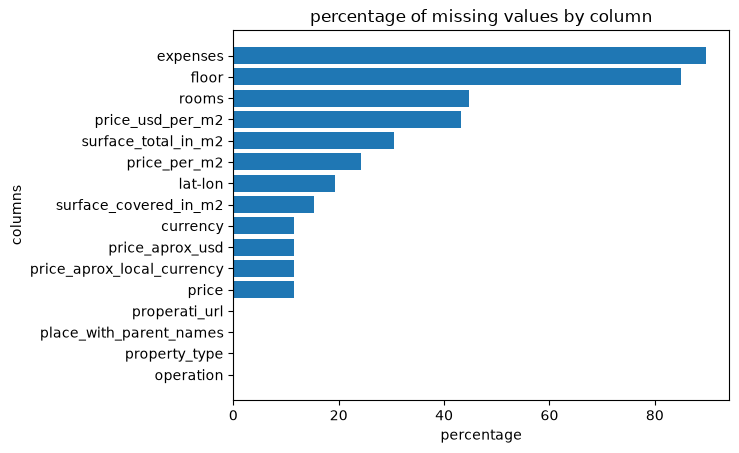

In [18]:
#percentage of missing values per column
nan_columns_percentage=(df.isna().sum() * 100/len(df)).sort_values()

fig,ax=plt.subplots()
ax.barh(y=nan_columns_percentage.index,width=nan_columns_percentage)
ax.set_title("percentage of missing values by column")
ax.set_xlabel("percentage")
ax.set_ylabel("columns")
plt.show()

In [19]:
print(nan_columns_percentage)

operation                      0.000000
property_type                  0.000000
place_with_parent_names        0.000000
properati_url                  0.000000
price                         11.517814
price_aprox_local_currency    11.517814
price_aprox_usd               11.517814
currency                      11.520138
surface_covered_in_m2         15.359409
lat-lon                       19.277696
price_per_m2                  24.139534
surface_total_in_m2           30.579377
price_usd_per_m2              43.180181
rooms                         44.674522
floor                         84.882289
expenses                      89.653490
dtype: float64


The missingno library in Python helps you visualize missing values in a dataset. It makes it easier to see which columns have missing data, how much data is missing, and whether missing values follow a pattern.

In [20]:
! pip install missingno -q

In [21]:
import missingno as msno


/opt/anaconda3/envs/buenos-env/lib/python3.13/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


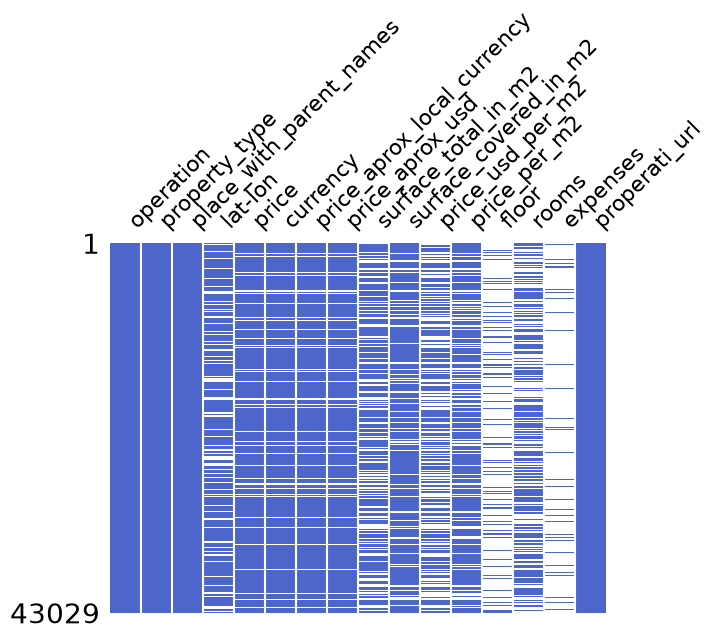

In [22]:
fig ,ax=plt.subplots()
msno.matrix(df,color=(0.3,0.4,0.8),ax=ax)
plt.show()

In [23]:
column_list=[ 'price', 'currency', 'price_aprox_local_currency','price_per_m2','floor', 'expenses']
def drop_columns(data):
    return data.drop(columns=column_list)


In [24]:
new_data =drop_columns(df)


In [25]:
new_data.columns

Index(['operation', 'property_type', 'place_with_parent_names', 'lat-lon',
       'price_aprox_usd', 'surface_total_in_m2', 'surface_covered_in_m2',
       'price_usd_per_m2', 'rooms', 'properati_url'],
      dtype='str')

In [26]:
df.columns

Index(['operation', 'property_type', 'place_with_parent_names', 'lat-lon',
       'price', 'currency', 'price_aprox_local_currency', 'price_aprox_usd',
       'surface_total_in_m2', 'surface_covered_in_m2', 'price_usd_per_m2',
       'price_per_m2', 'floor', 'rooms', 'expenses', 'properati_url'],
      dtype='str')

##  Multicollinearity Analysis

**Multicollinearity** occurs when two or more predictors in a regression model are highly correlated, meaning they provide overlapping or similar information about the target variable.

if both predictors provide similar information, it can be difficult for a regression model to distinguish their individual effects on the housing price.
Why is multicollinearity a problem?
- It makes individual regression coefficients(weight) less reliable.
- Coefficients may become unstable or have unexpected signs.
    | Predictor      | Model 1 coefficient | Model 2 coefficient |
|----------------|---------------------|---------------------|
| Total area     | +$1,000             | +$3,000             |
| Covered area   | +$500               | -$1,000             |

    - in Model 1, the coefficient for total area is $1,000. In Model 2, it is $3,000.
    - Why did it change so much when you only made a small change to the data?
    Because total area and covered area provide similar information. The model struggles to distinguish how much each one contributes independently to price.
That is an unstable coefficient: its estimated value changes significantly when the data or model changes slightly.
- It becomes harder to interpret the individual effect of each predictor.

#### What to do when you find multicollinear features:

Two main options:

1. Drop one: Keep the more interpretable or more complete feature. Drop the other.
2. Create a composite feature: Combine both into a single new column (e.g., ratio of covered to total area as a measure of how "enclosed" the apartment is). This preserves information from both columns.

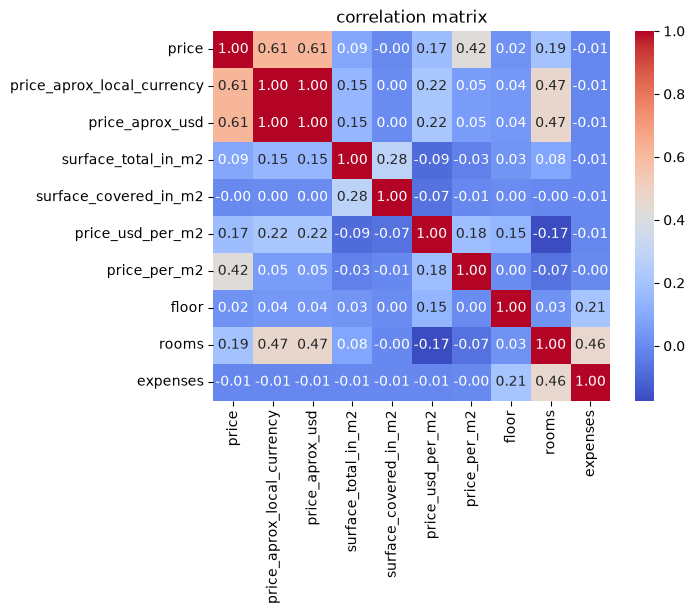

In [29]:
# calculate correlation matrix for numeric columns
corr_matrix=df.select_dtypes(include="number").corr()
fig,ax=plt.subplots()
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm',ax=ax)
ax.set_title("correlation matrix")
plt.show()

**Data leakage** happens when your model uses information during training that would not legitimately be available when making real-world predictions.

In [32]:
df["operation"].unique()


<StringArray>
['sell']
Length: 1, dtype: str

In [ ]:
drop_cols=['operation',"property_type",'property_url','surface_total_in_m2',
 'lat-lon','price','place_with_parent_names', 'currency', 'price_aprox_local_currency',
 'price_per_m2','rooms','floor','price_usd_per_m2', 'expenses']

In [43]:
def clean_files(file_path):
    drop_cols=['operation',"property_type",'properati_url','surface_total_in_m2',
 'lat-lon','price','place_with_parent_names', 'currency', 'price_aprox_local_currency',
 'price_per_m2','rooms','floor','price_usd_per_m2', 'expenses']
    return (merge_files(file_path)
    .pipe(filter_df)
    .pipe(outliers_df)
    .pipe(modify_cols)
    .drop(columns=drop_cols)
    )
clean_df=clean_files("../data/buenos-aires-real-estate-*.csv")
clean_df.info()
    

<class 'pandas.DataFrame'>
Index: 6247 entries, 7 to 43026
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        6247 non-null   float64
 1   surface_covered_in_m2  6247 non-null   float64
 2   lat                    6247 non-null   float64
 3   lon                    6247 non-null   float64
 4   neighbourhood          6247 non-null   str    
dtypes: float64(4), str(1)
memory usage: 292.8 KB


In [40]:
clean_df.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,neighbourhood
7,120000.0,55.0,-34.616004,-58.470506,Villa General Mitre
20,89000.0,37.0,-34.584712,-58.444927,Palermo
21,183495.0,57.0,-34.554652,-58.493644,Saavedra
41,95000.0,47.0,-34.610581,-58.479625,Villa del Parque
43,95000.0,35.0,-34.558227,-58.458357,Belgrano


### The correct sequence: 
1. clean data 
2. X/y split 
3. train-test split 
4.  encoding (inside the pipeline, fit on training only).

In [44]:
target="price_aprox_usd"
features= [cols for cols in clean_df.columns if cols not in target]

In [45]:
X=clean_df[features]
y=clean_df[target]

print(f"y shape: {y.shape}")
print(f"X shape: {X.shape}")

y shape: (6247,)
X shape: (6247, 4)


One-hot encoding creates a separate column for each unique category in a categorical variable. Each row gets:
- 1 if the category is present.
- 0 if the category is not present.

In [47]:
clean_df["neighbourhood"].nunique()

56

# One-Hot Encoding Many Categories

When we use one-hot encoding on 50+ Buenos Aires neighborhoods, we create many new columns. This can cause four problems.

### 1. Curse of Dimensionality
This means having too many features compared to the amount of data available.

**Example:** Palermo has 2,000 property listings, but another neighborhood has only 15. The model has more data to learn about Palermo than the other neighborhood.

### 2. Overfitting
Overfitting happens when a model learns the training data too well, including patterns that do not apply to new data.

**Example:** A neighborhood has only five houses, and all are expensive. The model might incorrectly learn that every house in that neighborhood is expensive.

### 3. Sparse Data
One-hot encoding creates many zeros in the dataset.

**Example:** If we have 50 neighborhood columns, a property belonging to one neighborhood will have a `1` in its neighborhood column and `0` in the other 49 columns.

This is called sparse data. It is not necessarily a problem, but storing and working with large datasets like this can require more resources.

### 4. Computational Cost
More columns can make a model take longer to train and use more memory.

However, 50 extra columns are usually manageable. This becomes a bigger concern when there are hundreds or thousands of categories.

## Why Use `category_encoders`?

The library can help create readable column names, such as `neighborhood_Palermo`.

This makes it easier to understand which neighborhood each column represents. Scikit-learn can also create readable names.


**Remember:** Having many categories does not automatically make a model bad. The important thing is whether we have enough data to learn reliable patterns and predict prices accurately.

In [48]:
from sklearn.model_selection import train_test_split

In [50]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

Training set: 4997 samples
Test set: 1250 samples


**Generalization**

Generalization is a model's ability to perform well on new, unseen data after training on a specific dataset.

**Overfitting**

Overfitting happens when a model memorizes patterns in the training data instead of learning patterns that generalize to new data.

# Overfitting: 

Overfitting happens when a model memorizes patterns in training data instead of learning relationships that work well on new data.

## Common Causes of Overfitting

**1. Model too complex**

A model has too many parameters compared with the amount of training data available. It may learn noise instead of general patterns.

**2. Irrelevant features**

Some columns do not help predict the target but may allow the model to memorize the training data.

Example: `properati_url` identifies a property listing. It is unlikely to help predict the price of a new property.

**3. Outliers**

Extreme values can influence a model's learned relationships, especially in linear regression, making predictions less reliable for typical properties.

Note: Outliers should be investigated before removal because some are genuine observations.

**4. Data leakage**

The model uses information that would not legitimately be available when making a prediction.

Example: Using `price_per_m2`, calculated from the actual property price, to predict that same price gives the model information about the answer.

## How to Recognize Overfitting

A common sign is a large gap between training and test performance.

Example:
- Training accuracy: 95%
- Test accuracy: 60%

The model performs much better on the training data than on unseen data, suggesting overfitting.

For a regression model predicting housing prices, we usually compare metrics such as MAE, RMSE, or \(R^2\), rather than classification accuracy.

## Preventing Overfitting in Our Housing Project

**1. Train-test split:** Separate the data into training and test sets to check how well the model performs on unseen properties.

**2. Feature selection:** Remove irrelevant columns, such as `properati_url`, that may encourage memorization.

**3. Outlier handling:** Investigate extreme prices and areas, then remove or handle them only when justified.

**4. Prevent data leakage:** Remove features derived from the target price so the model learns from genuine predictors.

**5. Reduce market differences:** Focus on apartments in Capital Federal to make the properties more comparable and reduce variation the model must handle.

**Key takeaway:** The goal is not to make a model perform perfectly on training data. The goal is to help it learn reliable patterns that predict prices accurately for properties it has never seen.